We have 60 weeks before launch and 20 campaign weeks. One observation is one city in one week; the outcome is completed rides. We estimate the campaign's effect on the pilot city, not the effect of redeeming a discount on individual riders.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Case-study city-week data.
# A fixed donor relationship and independent noise make this a clean example.
rng = np.random.default_rng(9)
week = np.arange(80)
donors = np.column_stack([
    900 + 65*j + (2 + 0.3*j)*week
    + (35 + 4*j)*np.sin(2*np.pi*week/26 + 0.15*j)
    + rng.normal(0, 12, len(week)) for j in range(8)
])
true_weights = np.array([0.45, 0, 0.35, 0, 0.20, 0, 0, 0])
untreated = donors @ true_weights + rng.normal(0, 8, len(week))
true_effect = 80  # Simulation input, never supplied to the estimator.
observed = untreated + true_effect*(week >= 60)
pre, post = np.arange(60), np.arange(60, 80)

def fit_weights(target, pool, training):
    # Only the supplied earlier weeks select the weights.
    # Nonnegative weights sum to one, so we blend rather than extrapolate.
    scale = target[training].mean()
    fit = minimize(
        lambda w: np.mean(((target[training] - pool[training] @ w)/scale)**2),
        np.full(pool.shape[1], 1/pool.shape[1]),
        bounds=[(0, 1)]*pool.shape[1],
        constraints={"type": "eq", "fun": lambda w: w.sum()-1},
        method="SLSQP", options={"ftol": 1e-12, "maxiter": 2000})
    if not fit.success:
        raise RuntimeError(fit.message)
    return fit.x

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual-predicted)**2))

#### Inspect the data and build the comparison
Before fitting anything, check what the rows represent and whether the other cities could be fair comparisons. In a real study, we'd check campaign exposure, shared travel, local events, and measurement changes. Here the comparison cities are unaffected by construction.

Now ask whether a blend of these cities follows the pilot before the campaign. Fit the weights on the first 40 weeks and test the prediction on the next 20. Those held-out weeks let us check performance on data that did not choose the weights.

Raw data preview:
 Week    City  Completed rides  Campaign active
    0 Donor 1           890.37            False
    1 Donor 1           913.29            False
    2 Donor 1           900.39            False
    0   Pilot          1005.81            False
    1   Pilot          1032.23            False
    2   Pilot          1025.95            False


,Period,"Prediction error, RMSE (rides/week)"
0,Fit: weeks 0-39,6.84
1,Validate: weeks 40-59,6.88


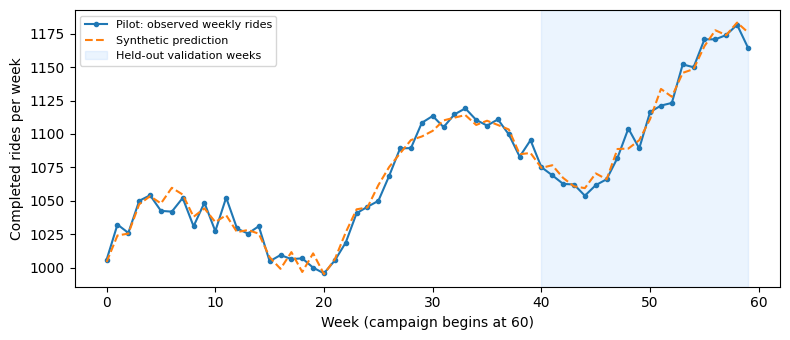

In [2]:
# Inspect the panel: one row is one city's outcome in one week.
panel = pd.DataFrame(donors, columns=[f"Donor {j+1}" for j in range(8)])
panel["Pilot"] = observed
panel["Week"] = week
panel = panel.melt(id_vars="Week", var_name="City", value_name="Completed rides")
panel["Campaign active"] = (panel.City == "Pilot") & (panel.Week >= 60)
# These synthetic counts are continuous for simplicity, not real transactions.
preview = panel[(panel.Week < 3) & panel.City.isin(["Pilot", "Donor 1"])]
print("Raw data preview:")
print(preview.round(2).to_string(index=False))

# Learn on weeks 0-39, then test on weeks 40-59 without refitting.
# Both periods precede the campaign. No later result chooses the weights.
w = fit_weights(observed, donors, np.arange(40))
synthetic = donors @ w
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(week[:60], observed[:60], "o-", markersize=3, label="Pilot: observed weekly rides")
ax.plot(week[:60], synthetic[:60], "--", label="Synthetic prediction")
ax.axvspan(40, 59, color="#60a5fa", alpha=.12, label="Held-out validation weeks")
ax.set(xlabel="Week (campaign begins at 60)", ylabel="Completed rides per week")
ax.legend(fontsize=8)
fig.tight_layout()
pd.DataFrame({
    "Period": ["Fit: weeks 0-39", "Validate: weeks 40-59"],
    "Prediction error, RMSE (rides/week)": [
        rmse(observed[:40], synthetic[:40]),
        rmse(observed[40:60], synthetic[40:60])],
}).round(2)

The preview shows city-week observations. The chart then compares actual pilot rides with the weighted prediction. Its shaded region is the 20-week validation period, still before launch.

The prediction error is 6.84 rides per week while fitting and 6.88 in validation. RMSE summarizes the size of the prediction errors, with larger misses counting more. The similar errors and close tracking support continuing in this example. If the prediction drifted away during validation, we'd revisit the comparison before estimating a campaign effect.

#### Estimate the campaign's lift

The earlier comparison looks usable. Refit the weights on all 60 prelaunch weeks, then freeze them. During the campaign, subtract the synthetic prediction from the pilot's actual rides each week.



Comparison weights, chosen before launch:
 Donor  Weight
     1   0.375
     2   0.093
     3   0.365
     4   0.015
     5   0.132
     6   0.020
     7   0.000
     8   0.000


,Quantity,Value
0,Prelaunch prediction error (rides/week),6.74
1,Initial average lift (rides/week),83.89
2,Initial total lift over 20 weeks (rides),1677.78
3,True effect set in the data setup (rides/week),80.00


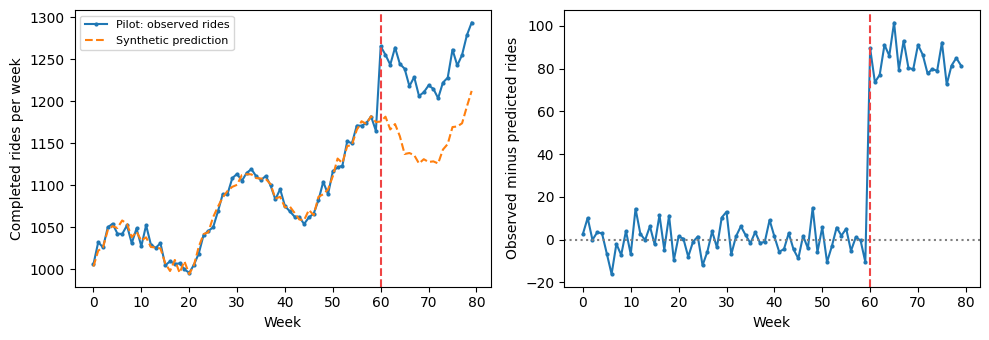

In [3]:
# The earlier validation passed. Refit on all 60 prelaunch weeks,
# then hold the weights fixed throughout the campaign.
w = fit_weights(observed, donors, pre)
synthetic = donors @ w
gap = observed - synthetic
print("Comparison weights, chosen before launch:")
print(pd.DataFrame({"Donor": np.arange(1, 9), "Weight": w}).round(3).to_string(index=False))

# Show the observed points as well as the prediction and their difference.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(week, observed, "o-", markersize=2, label="Pilot: observed rides")
ax[0].plot(week, synthetic, "--", label="Synthetic prediction")
ax[0].legend(fontsize=8)
ax[0].set(xlabel="Week", ylabel="Completed rides per week")
ax[1].plot(week, gap, "o-", markersize=2)
ax[1].axhline(0, color="gray", linestyle=":")
ax[1].set(xlabel="Week", ylabel="Observed minus predicted rides")
for axis in ax:
    axis.axvline(60, color="#ef4444", linestyle="--", label="Campaign begins")
fig.tight_layout()
pd.DataFrame({
    "Quantity": ["Prelaunch prediction error (rides/week)",
                 "Initial average lift (rides/week)",
                 "Initial total lift over 20 weeks (rides)",
                 "True effect set in the data setup (rides/week)"],
    "Value": [rmse(observed[pre], synthetic[pre]), gap[post].mean(),
              gap[post].sum(), true_effect],
}).round(2)


Donors 1, 3, and 5 carry most of the weight. That tells us which cities the comparison relies on, not how much each city causes the pilot's rides.

The initial estimate is 83.89 extra rides per week, or about 1,678 across 20 weeks. The code deliberately generated an effect of 80 per week; the estimate differs because of noise and prediction error. In a real study, we would not know that true effect.

This is a promising gap, not yet a launch recommendation. Next, check whether the result depends heavily on the cities we chose.

#### Check whether the comparison holds up

We'll make two checks. 

First, pretend each untreated city received the campaign. If they also show unusual gaps, our pilot may not be special. Second, remove each heavily weighted donor in turn. If the estimated lift changes sharply, the conclusion may depend on one particular comparison city.

For the placebo check, compare each city's later prediction error with its earlier error. A ratio near 1 means similar errors before and after launch; a large ratio means a much bigger miss afterward. Always inspect the earlier fit too.

Placebo checks (errors in rides/week):
   City  Earlier RMS error  Later/earlier error ratio
  Pilot               6.74                      12.50
Donor 1              80.34                       1.12
Donor 2              13.44                       1.05
Donor 3              13.94                       0.89
Donor 4              13.21                       1.00
Donor 5              12.61                       1.13
Donor 6              15.43                       0.92
Donor 7              14.65                       0.79
Donor 8              76.28                       1.10


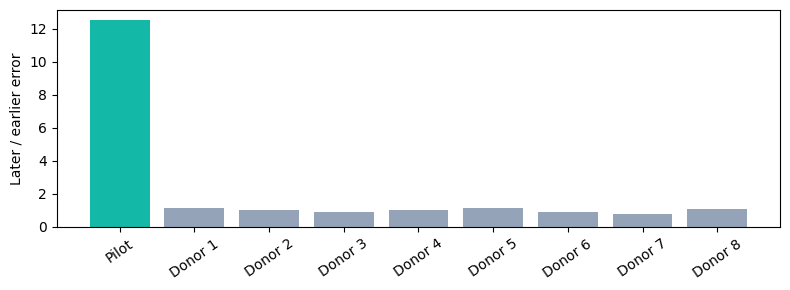

In [4]:
# Check 1: pretend each untreated city received the campaign.
# Never use the real pilot as a donor: its later outcomes include treatment.
targets = [("Pilot", observed, donors)]
targets += [(f"Donor {j+1}", donors[:, j], np.delete(donors, j, axis=1))
            for j in range(8)]
rows = []
for name, target, pool in targets:
    weights = fit_weights(target, pool, pre)
    error = target - pool @ weights
    pre_rms = np.sqrt(np.mean(error[pre]**2))
    post_rms = np.sqrt(np.mean(error[post]**2))
    rows.append({"City": name, "Earlier RMS error": pre_rms,
                 "Later/earlier error ratio": post_rms/pre_rms})
placebos = pd.DataFrame(rows)
print("Placebo checks (errors in rides/week):")
print(placebos.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(placebos.City, placebos["Later/earlier error ratio"],
       color=["#14b8a6"] + ["#94a3b8"]*8)
ax.set(ylabel="Later / earlier error")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()


In [5]:
# Check 2: remove each of the three largest-weight donors, one at a time.
# Identify them from prelaunch weights, not by which removal changes lift most.
w = fit_weights(observed, donors, pre)
sensitivity = [{"Comparison": "All donors",
                "Prelaunch RMSE": rmse(observed[pre], (donors @ w)[pre]),
                "Average lift": (observed - donors @ w)[post].mean()}]
for j in np.sort(np.argsort(w)[-3:]):
    pool = np.delete(donors, j, axis=1)
    reduced_w = fit_weights(observed, pool, pre)
    prediction = pool @ reduced_w
    sensitivity.append({
        "Comparison": f"Without donor {j+1}",
        "Prelaunch RMSE": rmse(observed[pre], prediction[pre]),
        "Average lift": (observed - prediction)[post].mean(),
    })
# All numeric columns below are rides per week.
pd.DataFrame(sensitivity).round(2)

,Comparison,Prelaunch RMSE,Average lift
0,All donors,6.74,83.89
1,Without donor 1,10.00,84.08
2,Without donor 3,8.44,82.72
3,Without donor 5,6.97,84.33


The pilot's later-to-earlier error ratio is 12.50; the placebo ratios range from 0.79 to 1.13. The pilot stands out. But donors 1 and 8 had much worse earlier fits, with errors of 80.34 and 76.28 rides versus 6.74 for the pilot. They are weak benchmarks, so the chart alone does not establish significance.

Removing donors 1, 3, and 5 one at a time gives lifts of 84.08, 82.72, and 84.33 rides per week. Those remain close to 83.89. Earlier fit gets somewhat worse, but no single removal reverses the conclusion. That supports continuing to uncertainty estimation; it does not rule out a separate event affecting only the pilot.

Why isn't the city-placebo ranking our p-value?
With eight placebos, even first place gives a rank of 1 out of 9, about 0.111. Interpreting the rank as a p-value also needs a defensible reason to compare treatment assignments across cities. The pilot was deliberately selected and the fits differ. We therefore use these placebos as a diagnostic, not a formal 5% test. 

#### How sure are we about the lift?

The estimate survives those checks. Now we need an interval and a test of zero average effect over the 20 campaign weeks. That is a different question from whether each week shows a significant increase.

We'll use a cross-fitted synthetic-control t-test. Leave out a 20-week block from the earlier data and fit on the remaining 40 weeks. Measure the prediction error in the omitted block, then subtract that earlier error from the campaign gap. Repeat for all three blocks.

This produces an adjusted estimate and an uncertainty calculation that accounts for the campaign weeks shared across the fits. It is not an ordinary t-test on the 20 weekly gaps. We choose this procedure before checking its p-value.

In [6]:
from scipy.stats import t as student_t

# Prespecify three consecutive held-out blocks; do not tune K to significance.
K = 3
r = min(len(pre)//K, len(post))
rows = []
for k in range(K):
    held_out = pre[k*r:(k+1)*r]
    training = np.setdiff1d(pre, held_out)
    weights = fit_weights(observed, donors, training)
    error = observed - donors @ weights
    earlier_error = error[held_out].mean()
    campaign_gap = error[post].mean()
    rows.append({
        "Held-out weeks": f"{held_out[0]} to {held_out[-1]}",
        "Campaign gap": campaign_gap,
        "Earlier error": earlier_error,
        "Adjusted lift": campaign_gap - earlier_error,
    })
folds = pd.DataFrame(rows)
print("Prediction-error correction (rides/week):")
print(folds.round(2).to_string(index=False))

# Specialized cross-fitted SC inference, not an ordinary weekly-gap t-test.
# The scaling accounts for campaign weeks shared by all three estimates.
# Source: Chernozhukov, Wuthrich and Zhu, Section 2.2, equations (4)-(6).
estimate = folds["Adjusted lift"].mean()
se = np.sqrt(1 + K*r/len(post)) * folds["Adjusted lift"].std(ddof=1) / np.sqrt(K)
df = K - 1
alpha = 0.05
t_stat = estimate / se
p_value = 2 * student_t.sf(abs(t_stat), df=df)
critical = student_t.ppf(1 - alpha/2, df=df)
lower, upper = estimate - critical*se, estimate + critical*se

# The interval describes the average effect, not each individual week.
pd.DataFrame({
    "Quantity": ["Adjusted average lift (rides/week)",
                 "Standard error (rides/week)", "Approximate 95% CI (rides/week)",
                 "Test statistic", "Degrees of freedom", "Two-sided p-value",
                 "Significant at 5% under the model?"],
    "Value": [f"{estimate:.2f}", f"{se:.2f}", f"[{lower:.2f}, {upper:.2f}]",
              f"{t_stat:.2f}", str(df), f"{p_value:.6f}",
              "Yes" if p_value < alpha else "No"],
})

Prediction-error correction (rides/week):
Held-out weeks  Campaign gap  Earlier error  Adjusted lift
       0 to 19         84.51           1.25          83.26
      20 to 39         84.20           0.61          83.59
      40 to 59         82.95          -2.05          85.00


,Quantity,Value
0,Adjusted average lift (rides/week),83.95
1,Standard error (rides/week),1.07
2,Approximate 95% CI (rides/week),"[79.36, 88.54]"
3,Test statistic,78.63
4,Degrees of freedom,2
5,Two-sided p-value,0.000162
6,Significant at 5% under the model?,Yes


What we found: the adjusted estimate is 83.95 extra rides per week. For example, the first fit already underpredicted rides by 1.25 before launch, so its adjusted lift is 84.51 − 1.25 = 83.26. Averaging the three corrected estimates gives 83.95. This replaces the initial 83.89 for the final inference; we do not attach the new interval to the old estimate.

How sure we are: the approximate 95% interval is 79.36 to 88.54 extra rides per week, and p = 0.000162 is below the stated 0.05 threshold. Under this model, the data provide evidence against zero average effect. The interval describes the campaign average in this city, not every week's lift or the result in other cities.

What assumptions does this significance result need?
The weighted cities must remain a reliable guide to the pilot's no-campaign path. Prediction errors must have a stable pattern, and dependence over time must fade sufficiently. The data setup uses a fixed donor relationship and independent noise. With only 60 earlier and 20 later weeks, this is an approximate interval, not guaranteed coverage.

This test uses information over time, so it is not limited by the nine-city placebo ranking. It relies on different assumptions, not a trick for making the placebo p-value smaller. A small p-value cannot rule out an unmeasured event affecting only the pilot.

What we'd recommend: this case study supports a positive lift in the pilot, conditional on the comparison remaining valid. We have not measured campaign profitability, cancellations, wait times, or driver earnings, so we cannot yet recommend a broad rollout. Check those outcomes and the pilot's event history first. If the benefit clears costs and service quality holds up, test the offer in additional comparable cities, with random assignment where feasible.